# 2 · Market regimes with a Hidden Markov Model (built from scratch)
Weekly SPY returns are modelled as a Gaussian HMM. The implementation in `riskmodels.hmm` uses scaled **forward-backward** recursions, **Viterbi** decoding and **Baum-Welch** EM with random restarts. It is validated against brute-force enumeration in the tests and against `hmmlearn` below.

The models are then used **out-of-sample**: parameters are estimated on 2000-2014, and from 2015 onwards only the *filtered* (real-time) regime probability drives a simple risk-on/risk-off allocation.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
spy = pd.read_csv("../data/spy_daily.csv", index_col=0, parse_dates=True)["SPY"]   # refresh: python scripts/fetch_data.py
from riskmodels import hmm

In [2]:
w = np.log(spy.resample("W-FRI").last()).diff().dropna()
fits = {K: hmm.baum_welch(w.values, K=K, seed=1, n_restarts=10)[0] for K in (1, 2, 3, 4)}
sel = pd.DataFrame({K: {"log-lik": m.log_likelihood(w.values), "BIC": hmm.bic(m, w.values)} for K, m in fits.items()}).T
sel.index.name = "states"; sel.round(1)

,log-lik,BIC
states,,
1,3197.5,-6380.6
2,3418.4,-6786.1
3,3452.8,-6804.1
4,3478.1,-6789.7


In [3]:
from hmmlearn.hmm import GaussianHMM as HL
ref = HL(n_components=3, covariance_type="diag", n_iter=500, random_state=1).fit(w.values.reshape(-1, 1))
print(f"log-likelihood: this implementation {fits[3].log_likelihood(w.values):.2f} | hmmlearn {ref.score(w.values.reshape(-1, 1)):.2f}")

log-likelihood: this implementation 3452.77 | hmmlearn 3427.42


In [4]:
m = fits[3]
names = ["Bear", "Stagnant", "Bull"]
summary = pd.DataFrame({"weekly mean": m.mu, "ann. return": m.mu * 52, "ann. vol": m.sigma * np.sqrt(52),
                        "expected duration (weeks)": m.expected_duration(), "long-run share": m.stationary()}, index=names)
display(summary.style.format({"weekly mean": "{:.3%}", "ann. return": "{:.1%}", "ann. vol": "{:.1%}", "expected duration (weeks)": "{:.1f}", "long-run share": "{:.1%}"}))
pd.DataFrame(m.A, index=names, columns=names).round(3)

,weekly mean,ann. return,ann. vol,expected duration (weeks),long-run share
Bear,-1.853%,-96.3%,54.6%,4.9,3.1%
Stagnant,-0.038%,-2.0%,20.2%,15.2,37.6%
Bull,0.382%,19.9%,10.0%,32.3,59.2%


,Bear,Stagnant,Bull
Bear,0.797,0.203,0.000
Stagnant,0.017,0.934,0.049
Bull,0.000,0.031,0.969


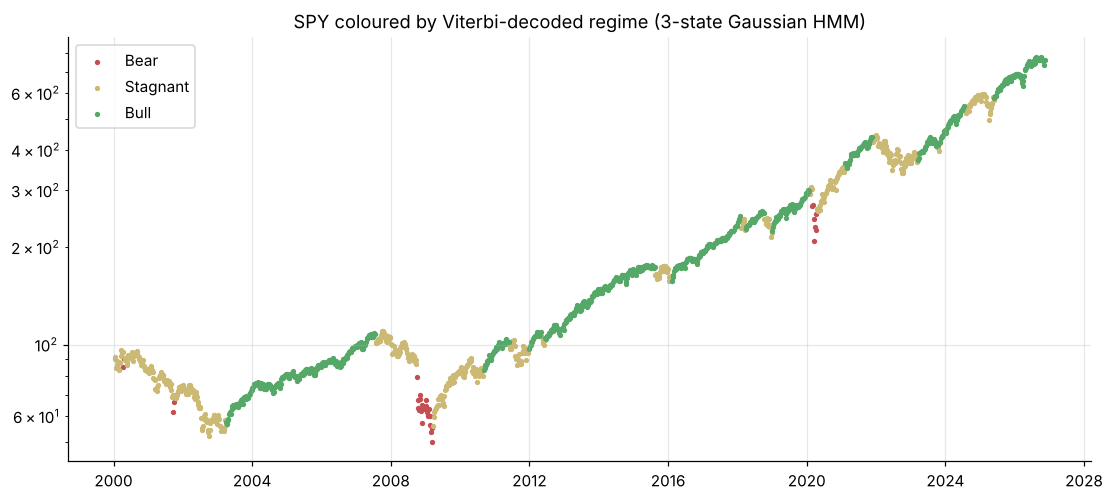

In [5]:
states = m.viterbi(w.values)
price = spy.resample("W-FRI").last().loc[w.index]
fig, ax = plt.subplots(figsize=(12, 5))
cols = ["#C44E52", "#CCB974", "#55A868"]
for k in range(3):
    ax.scatter(price.index[states == k], price[states == k], s=6, color=cols[k], label=names[k])
ax.set_yscale("log"); ax.legend(); ax.set_title("SPY coloured by Viterbi-decoded regime (3-state Gaussian HMM)")
plt.savefig(IMG / "hmm_regimes.png", bbox_inches="tight"); plt.show()

## Out-of-sample: real-time regime filtering

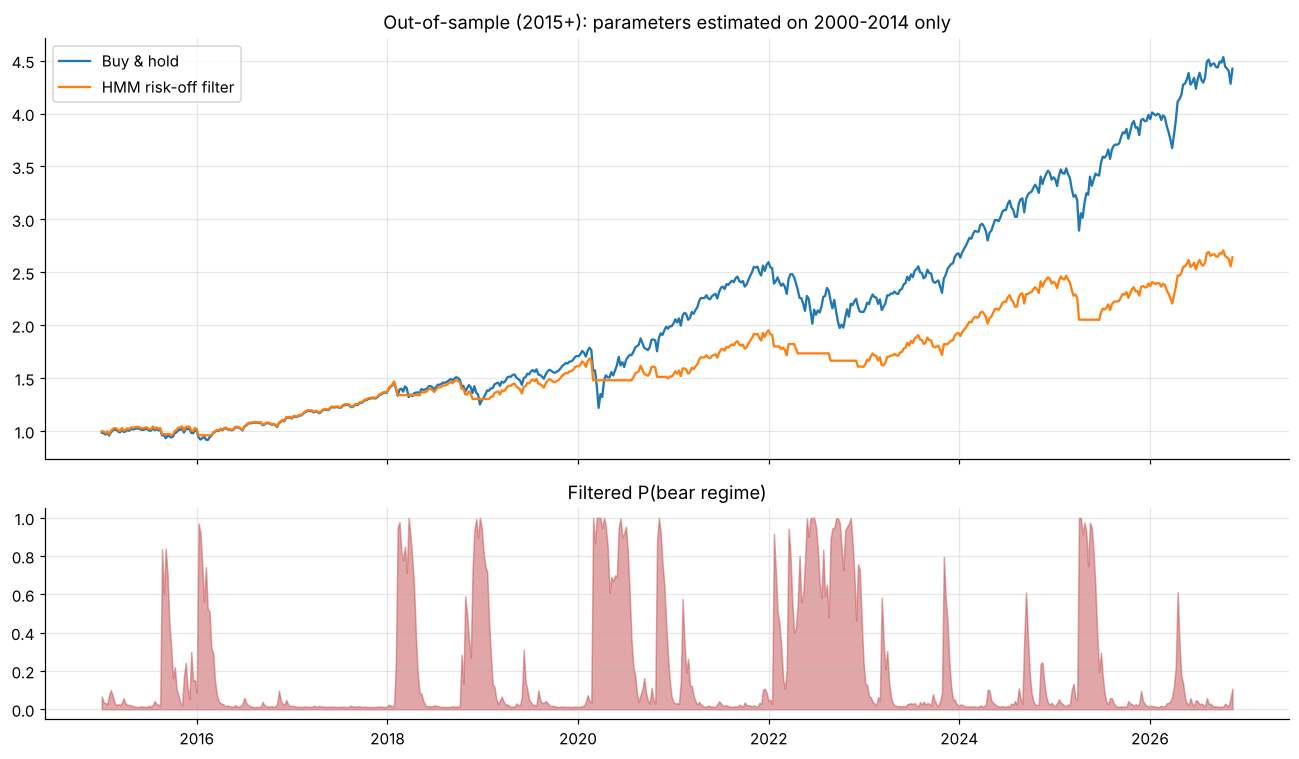

,CAGR,vol,Sharpe (vs 0),max DD,time invested
Buy & hold,13.3%,16.6%,0.75,-31.8%,100%
HMM risk-off filter,8.5%,12.2%,0.67,-17.6%,82%


In [6]:
train, test = w.loc[:"2014-12-31"], w.loc["2015-01-01":]
m_tr = hmm.baum_welch(train.values, K=2, seed=1, n_restarts=10)[0]       # 2 states: bear (0) vs bull (1)
# filtered P(state | data up to t) = scaled forward variable; run over full history, use test part only
alpha, _, _, _ = m_tr.forward_backward(w.values)
p_bear_now = pd.Series(alpha[:, 0], index=w.index).loc[test.index]
pos = (p_bear_now.shift(1) < 0.5).astype(float)                          # decide with last week's info
strat = pos * test                                                        # in cash (0%) when bearish
curves = pd.DataFrame({"Buy & hold": test.cumsum(), "HMM risk-off filter": strat.cumsum()}).apply(np.exp)
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for c in curves: ax[0].plot(curves.index, curves[c], label=c)
ax[0].legend(); ax[0].set_title("Out-of-sample (2015+): parameters estimated on 2000-2014 only")
ax[1].fill_between(p_bear_now.index, p_bear_now, color="#C44E52", alpha=0.5); ax[1].set_title("Filtered P(bear regime)")
fig.tight_layout(); plt.savefig(IMG / "hmm_oos.png", bbox_inches="tight"); plt.show()
def stats_(x):
    wealth = np.exp(x.cumsum()); return {"CAGR": wealth.iloc[-1] ** (52 / len(x)) - 1, "vol": x.std() * np.sqrt(52),
                                          "Sharpe (vs 0)": x.mean() / x.std() * np.sqrt(52), "max DD": (wealth / wealth.cummax() - 1).min(),
                                          "time invested": None}
res = pd.DataFrame({"Buy & hold": stats_(test), "HMM risk-off filter": stats_(strat)}).T
res.loc["HMM risk-off filter", "time invested"] = pos.mean(); res.loc["Buy & hold", "time invested"] = 1.0
res.style.format({"CAGR": "{:.1%}", "vol": "{:.1%}", "Sharpe (vs 0)": "{:.2f}", "max DD": "{:.1%}", "time invested": "{:.0%}"})

**Takeaways**
* BIC selects **three regimes**: a calm bull state (~10% vol, ~59% of the time), a choppy stagnant state, and a rare, short-lived crisis state (~55% vol, average duration about 5 weeks). The from-scratch EM with random restarts reaches a slightly *higher* likelihood than `hmmlearn`'s single run.
* The bear regime has much higher volatility and short expected durations. Regimes describe **volatility states** better than return states.
* Used in real time (2015+), the filter **nearly halved the maximum drawdown** (about −18% vs −32%) and cut volatility, but it **gave up return** (about 8.5% vs 13% CAGR) because it often stepped aside just before rebounds. It works as a risk-control overlay, not a return engine.